Total queries: 500
Min entropy: 2.520225
Max entropy: 14.032900


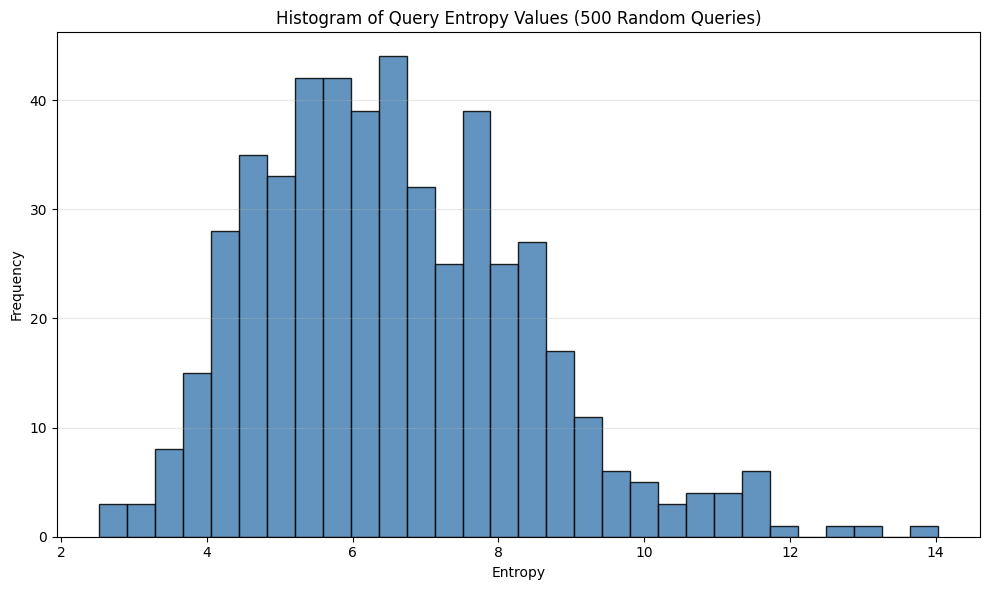

Saved histogram: entropy_histogram_500_queries.png


In [19]:
from pathlib import Path
import csv
import matplotlib.pyplot as plt

candidate_dirs = [
    Path("."),
    Path("plots/query_entropy_difficulty_mrr_exp"),
    Path("/Users/gokulrajkumarassamy/Programming/Research/entropy/plots/query_entropy_difficulty_mrr_exp"),
]

base_dir = None
for candidate in candidate_dirs:
    if (candidate / "queries_straightforward.csv").exists() and (candidate / "queries_moderate.csv").exists() and (candidate / "queries_complicated.csv").exists():
        base_dir = candidate
        break

if base_dir is None:
    raise FileNotFoundError("Could not locate the three query entropy CSV files.")

csv_files = [
    base_dir / "queries_straightforward.csv",
    base_dir / "queries_moderate.csv",
    base_dir / "queries_complicated.csv",
]

entropy_values = []
for csv_path in csv_files:
    with open(csv_path, "r", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for row in reader:
            entropy_values.append(float(row["query_entropy"]))

count = len(entropy_values)
min_entropy = min(entropy_values)
max_entropy = max(entropy_values)

print(f"Total queries: {count}")
print(f"Min entropy: {min_entropy:.6f}")
print(f"Max entropy: {max_entropy:.6f}")

plt.figure(figsize=(10, 6))
plt.hist(entropy_values, bins=30, color="steelblue", edgecolor="black", alpha=0.85)
plt.title("Histogram of Query Entropy Values (500 Random Queries)")
plt.xlabel("Entropy")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)

output_path = base_dir / "entropy_histogram_500_queries.png"
plt.tight_layout()
plt.savefig(output_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved histogram: {output_path}")

In [20]:
import pandas as pd

df = pd.read_csv("entropy_threshold_12.00_10passages_alphas_top_passage_mrr.csv")
df

,query_id,query_text,passage_id_0,passage_text_0,mrr_0,passage_id_0_2,passage_text_0_2,mrr_0_2
0,66707,can dolphins smell,7878849,While researchers believe that these marine ma...,0.333333,7878850,"Meanwhile, most toothed whales, including dolp...",0.250000
1,89610,cells bio definition,7315393,cell biology. noun. Medical Definition of cell...,1.000000,6121305,The word your cell bio teacher tells you (in c...,0.500000
2,116455,deep listening definition,7370295,"deep listening as “listening, from a deep, rec...",1.000000,7370295,"deep listening as “listening, from a deep, rec...",1.000000
3,117728,define anomaly,8561262,Wiktionary(5.00 / 1 vote)Rate this definition:...,0.000000,1791939,Anomaly definition: If something is an anomaly...,0.000000
4,119168,define coherent,3291255,coherent. adj. 1. capable of logical and consi...,0.200000,7357318,Definition of coherent for Students. 1 1 : lo...,0.500000
5,124787,define oppress,7588934,Learner's definition of OPPRESS. [+ object] 1....,1.000000,7588934,Learner's definition of OPPRESS. [+ object] 1....,1.000000
6,129228,define workflow,7414148,DEFINITION of 'Workflow'. A series of tasks to...,0.000000,6694086,Workflow management is the monitoring of the p...,0.000000
7,139767,definition quint,614250,What does quint mean in Urban Dictionary?: Meg...,0.166667,614250,What does quint mean in Urban Dictionary?: Meg...,0.166667
8,158887,do selfies flip,4534575,Most selfies are taken with a camera held at a...,0.000000,638716,"In 2009, selfies were discussed on a college l...",0.000000
9,184916,family roots definition,1116973,The definition of family is the group of peopl...,0.000000,714207,Freebase(0.00 / 0 votes)Rate this definition: ...,0.000000


In [21]:
df["mrr_0"].mean()

np.float64(0.3281144545454545)

In [22]:
df["mrr_0_2"].mean()

np.float64(0.32525248484848485)